# Market Making: the Avellaneda-Stoikov Model

Simulation of a market maker that quotes bid and ask dynamically as a function of its inventory, with the parameters of Section 4 of Avellaneda & Stoikov (2008), *High-frequency trading in a limit order book*.

* Reservation price: $r = s - q \gamma \sigma^2 (T-t)$
* Optimal spread: $\delta^a + \delta^b = \gamma \sigma^2 (T-t) + \frac{2}{\gamma}\ln\left(1 + \frac{\gamma}{k}\right)$
* Mid-price: random walk $s_{t+dt} = s_t \pm \sigma\sqrt{dt}$
* Fills: Poisson process with intensity $\lambda(\delta) = A e^{-k\delta}$

---
## 1. Simulation

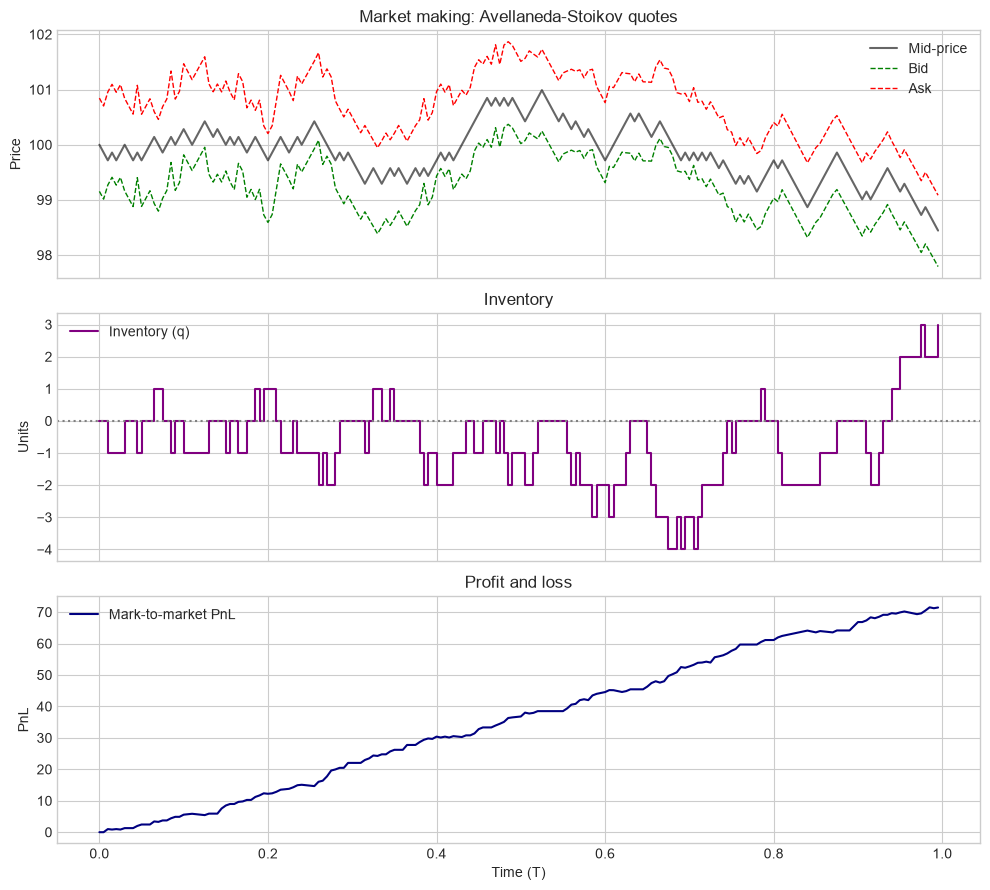

 gamma strategy              spread t=0  mean PnL  sd PnL  mean q   sd q
  0.01 Inventory (A-S)             1.37     68.35    8.91   -0.04   5.20
  0.01 Symmetric                   1.37     68.26   13.28   -0.03   8.53


   0.1 Inventory (A-S)             1.69     64.90    6.52    0.02   2.89


   0.1 Symmetric                   1.69     67.39   12.90    0.05   8.31
   0.5 Inventory (A-S)             3.15     48.59    5.79    0.08   1.93


   0.5 Symmetric                   3.15     58.32   11.29   -0.02   6.99


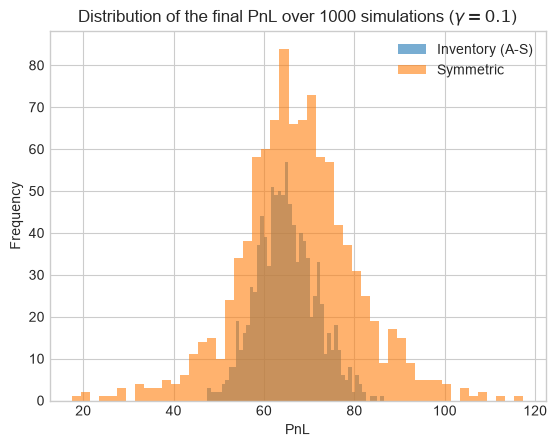

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Parameters of Section 4 of Avellaneda & Stoikov (2008)
S0, T, dt = 100.0, 1.0, 0.005
N = int(round(T / dt))
sigma = 2.0                    # absolute volatility of the mid-price (price units per unit of time)
k_param, A = 1.5, 140.0
t = np.arange(N + 1) * dt


def simulate(n_paths, inventory_aware, gamma=0.1, seed=42):
    """Simulate n_paths market-making sessions; return final PnL, final inventory and the first path.

    inventory_aware=True  -> quotes centred on the reservation price r = s - q*gamma*sigma^2*(T-t)
    inventory_aware=False -> quotes symmetric around the mid, with the same spread
    At each step each side is filled with probability lambda(delta)*dt = A*exp(-k*delta)*dt
    (at most one fill per side; when the probability exceeds 1 the fill is certain).
    """
    rng = np.random.default_rng(seed)
    s = np.full(n_paths, S0)
    q = np.zeros(n_paths)
    cash = np.zeros(n_paths)
    path = {'mid': [], 'bid': [], 'ask': [], 'q': [], 'pnl': []}

    for i in range(N):
        tau = T - t[i]
        spread = gamma * sigma**2 * tau + (2 / gamma) * np.log(1 + gamma / k_param)
        centre = s - q * gamma * sigma**2 * tau if inventory_aware else s
        bid, ask = centre - spread / 2, centre + spread / 2

        path['mid'].append(s[0]); path['bid'].append(bid[0])
        path['ask'].append(ask[0]); path['q'].append(q[0])
        path['pnl'].append(cash[0] + q[0] * s[0])

        delta_b, delta_a = s - bid, ask - s
        fill_bid = rng.random(n_paths) < A * np.exp(-k_param * delta_b) * dt
        fill_ask = rng.random(n_paths) < A * np.exp(-k_param * delta_a) * dt
        q += fill_bid.astype(float) - fill_ask
        cash += np.where(fill_ask, ask, 0.0) - np.where(fill_bid, bid, 0.0)

        # mid-price: binomial walk +-sigma*sqrt(dt), as in the paper
        s = s + sigma * np.sqrt(dt) * np.where(rng.random(n_paths) < 0.5, 1.0, -1.0)

    pnl = cash + q * s           # remaining inventory valued at the final mid
    path = {key: np.array(v) for key, v in path.items()}
    return pnl, q, path


# One path of the inventory-aware strategy (gamma = 0.1)
_, _, path = simulate(1, inventory_aware=True)
tt = t[:-1]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
ax1.plot(tt, path['mid'], 'k-', alpha=0.6, label='Mid-price')
ax1.plot(tt, path['bid'], 'g--', lw=1, label='Bid')
ax1.plot(tt, path['ask'], 'r--', lw=1, label='Ask')
ax1.set_title('Market making: Avellaneda-Stoikov quotes')
ax1.set_ylabel('Price')
ax1.legend()

ax2.step(tt, path['q'], where='post', color='purple', label='Inventory (q)')
ax2.axhline(0, color='gray', linestyle=':')
ax2.set_title('Inventory')
ax2.set_ylabel('Units')
ax2.legend()

ax3.plot(tt, path['pnl'], color='navy', label='Mark-to-market PnL')
ax3.set_title('Profit and loss')
ax3.set_xlabel('Time (T)')
ax3.set_ylabel('PnL')
ax3.legend()
plt.tight_layout()
plt.show()

# Monte Carlo comparison with the symmetric strategy for three levels of risk aversion,
# as in the paper's tables. The same seed for both strategies (common random numbers)
# makes the comparison less noisy.
n_sim = 1000
results = {}
print(f"{'gamma':>6} {'strategy':<20} {'spread t=0':>11} {'mean PnL':>9} {'sd PnL':>7} {'mean q':>7} {'sd q':>6}")
for gamma in [0.01, 0.1, 0.5]:
    spread0 = gamma * sigma**2 * T + (2 / gamma) * np.log(1 + gamma / k_param)
    for name, aware in [('Inventory (A-S)', True), ('Symmetric', False)]:
        pnl, q_final, _ = simulate(n_sim, aware, gamma=gamma, seed=7)
        results[(gamma, name)] = pnl
        print(f"{gamma:>6} {name:<20} {spread0:>11.2f} {pnl.mean():>9.2f} {pnl.std():>7.2f} "
              f"{q_final.mean():>7.2f} {q_final.std():>6.2f}")

plt.figure()
for name in ['Inventory (A-S)', 'Symmetric']:
    plt.hist(results[(0.1, name)], bins=50, alpha=0.6, label=name)
plt.title(f'Distribution of the final PnL over {n_sim} simulations ($\\gamma = 0.1$)')
plt.xlabel('PnL')
plt.ylabel('Frequency')
plt.legend()
plt.show()

## 2. Interpretation

* The symmetric strategy earns on average as much as or more than the Avellaneda-Stoikov strategy, but it accumulates inventory: the dispersion of the final inventory and of the PnL is about twice as large or more.
* The Avellaneda-Stoikov strategy skews its quotes against the inventory (with $q > 0$ it lowers both bid and ask to sell more easily), pulling $q$ back towards zero and reducing risk.
* A higher $\gamma$ widens the spread and makes inventory management more aggressive: lower risk in exchange for a lower mean PnL.

The next notebook, [`two_venue_adverse_selection.ipynb`](two_venue_adverse_selection.ipynb), adds what this model leaves out: the price is discovered on another venue, and part of the flow is informed.